<table style="width: 100%; border: none; background: #f8f9fa; padding: 20px; border-radius: 10px;">
    <tr>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://www.inf.ucv.cl/wp-content/uploads/2020/05/logo_escuela.jpg" width="170">
        </td>
        <td style="width: 56%; border: none; vertical-align: middle; text-align: center; padding: 0 20px;">
            <h1 style="font-size: 28px; color: #1a3b5c; margin-bottom: 16px; border-bottom: 2px solid #1a3b5c; padding-bottom: 8px;">Tarea 2: Clasificacion, Costos Asimetricos y Arboles</h1>
            <p style="font-size: 16px; margin: 8px 0;"><strong>Pontificia Universidad Catolica de Valparaiso</strong><br>
            <strong>Escuela de Ingenieria Informatica</strong></p>
            <p style="font-size: 14px; color: #333; margin: 12px 0;"><strong>OII432 Machine Learning</strong><br>
            <strong>Semestre: 2-2026</strong><br>
            <strong>Profesor: Carlos Valle</strong></p>
        </td>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://upload.wikimedia.org/wikipedia/commons/c/cb/PUCV_Escudo2016.svg" width="110">
        </td>
    </tr>
</table>

# Tarea 2: Clasificación, costos asimétricos y árboles

Objetivo: medir sobre datos reales los conceptos de clasificación, verosimilitud, evaluación con clases desbalanceadas y decisión bajo costos asimétricos, y luego llegar al primer ensemble del curso, el promedio de árboles, verificando empíricamente el teorema que lo gobierna.

Temas: pérdidas de clasificación, verosimilitud de Bernoulli y entropía cruzada, regresión logística, LDA y QDA, Naive Bayes, matriz de confusión, precision y recall, ROC, AUC y curva PR, el umbral como decisión económica, árboles de decisión, poda por costo-complejidad, bagging, Random Forest y out-of-bag.

Formalidades

* Los códigos de referencia son solo orientativos.
* Entregar un Jupyter Notebook (.ipynb) con código, análisis e interpretaciones en celdas markdown.
* Trabajo en grupos de 3 o 4. La copia parcial o total será penalizada con nota 1.
* Entregable subido a un repositorio privado de GitHub. Enviar el link a <carlos.valle@pucv.cl> (Asunto: [OII432-2-2026 Tarea2]) e invitar como colaborador al usuario **cvalle231**.
* Cierre del desafío Kaggle: **viernes 16 de octubre a las 10:59 am**.
* Fecha de entrega: **lunes 19 de octubre a las 1:30 pm**.
* Deben estar preparados para presentar su tarea en las clases del **viernes 16 de octubre**.

La tarea tiene dos partes de igual ponderación: la pregunta dirigida (50%) y el desafío Kaggle (50%).

# Pregunta 1: (50%) ¿Revisar el camión o dejarlo salir?

En la Tarea 1 el error se medía en megapascales y todos los errores costaban lo mismo. Aquí no. Trabajaremos con **APS Failure at Scania Trucks**, publicado por Scania CV AB: 60.000 camiones pesados en operación, 170 mediciones por camión y una etiqueta binaria que indica si la falla que llegó al taller correspondía al sistema de aire comprimido (APS), el que alimenta frenos y cambios.

El dataset trae tres propiedades que lo hacen el laboratorio exacto de este capítulo.

Primero, está **desbalanceado**: 1.000 positivos entre 60.000 camiones, un 1,67%. El clasificador perezoso de la clase acierta el 98,3% de las veces y no detecta un solo camión con falla.

Segundo, y esto es lo inusual, viene con el **precio de cada error puesto por la empresa**: revisar un camión sano cuesta 10 (una inspección innecesaria del mecánico), dejar pasar uno con falla cuesta 500 (la falla en ruta). El umbral deja de ser una convención en 0,5 y pasa a ser una cantidad que se puede *derivar*.

Tercero, las columnas son **contadores y bins de histogramas anonimizados**, con nombres del tipo `aa_000`, `ag_003`, y con muchísimos datos faltantes. No hay conocimiento de dominio al que apelar: la interpretación tendrá que salir del modelo, no del nombre de la variable.

El camionero del capítulo 1 vuelve, entonces, convertido en flota.

Esta parte se evalúa sobre 88 puntos, repartidos entre las subpreguntas según el trabajo que exige cada una. La nota se obtiene como:

$$\text{Nota Pregunta 1} = \frac{\text{puntos obtenidos}}{88} \times 6 + 1.$$

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, log_loss)
from sklearn.calibration import calibration_curve

plt.rcParams['figure.figsize'] = (12, 5)
sns.set_palette("deep")
np.random.seed(42)

# Parte 1: Los datos, el protocolo y el precio del error

## 1. Carga, faltantes y particion

### 1a) (2 pts) Carga el dataset APS Failure at Scania Trucks

El dataset está en el [repositorio UCI](https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks) como un zip de unos 54 MB con dos archivos: `aps_failure_training_set.csv` (60.000 camiones) y `aps_failure_test_set.csv` (16.000). **En esta tarea se usa solo el de entrenamiento**: lo particionarán ustedes en 1d).

No usen `ucimlrepo`: este dataset no está habilitado para importarse con esa librería. La celda de abajo descarga el zip una sola vez y lo deja en la carpeta del notebook. Si la descarga falla (por ejemplo, por la red de la universidad), bajen el zip a mano desde el enlace anterior y déjenlo en la misma carpeta del notebook con el nombre `aps_failure.zip`.

Tengan en cuenta dos detalles del archivo. Los CSV traen un encabezado de licencia de unas 20 líneas antes de los nombres de columna, y los faltantes vienen como la cadena `'na'`.

Deja los atributos en `X` (numéricos) y la etiqueta en `y` codificada como 1 para la clase positiva (falla del APS) y 0 para la negativa. Reporta cuántos camiones hay, cuántos atributos, y la proporción de positivos.

In [ ]:
import io, os, zipfile, urllib.request

URL_APS = "https://archive.ics.uci.edu/static/public/421/aps+failure+at+scania+trucks.zip"
ZIP_APS = "aps_failure.zip"

if not os.path.exists(ZIP_APS):
    urllib.request.urlretrieve(URL_APS, ZIP_APS)

def leer_csv_aps(zip_path, nombre="aps_failure_training_set.csv"):
    """Lee un CSV del zip de UCI (aunque venga dentro de otro zip) saltando la licencia."""
    zf = zipfile.ZipFile(zip_path)
    if nombre not in zf.namelist():                     # zip anidado
        interno = next(n for n in zf.namelist() if n.endswith(".zip"))
        zf = zipfile.ZipFile(io.BytesIO(zf.read(interno)))
    lineas = zf.read(nombre).decode("latin-1").splitlines()
    inicio = next(i for i, l in enumerate(lineas) if l.startswith("class,"))
    return pd.read_csv(io.StringIO("\n".join(lineas[inicio:])), na_values="na")

df = leer_csv_aps(ZIP_APS)

# TODO: separar atributos y target
X = df.drop(columns=["class"]).astype("float")
y = (df["class"] == "pos").astype(int).to_numpy()

print(f"Camiones: {X.shape[0]} | Atributos: {X.shape[1]}")
print(f"Positivos: {y.sum()} ({100 * y.mean():.2f}%)")
X.head()

Camiones: 60000 | Atributos: 170
Positivos: 1000 (1.67%)


,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,76698.0,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,33058.0,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,41040.0,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,12.0,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,318.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,60874.0,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### 1b) (3 pts) Caracteriza los datos faltantes

Calcula la fracción de faltantes por columna y grafica su distribución. Luego compara esa fracción **entre las dos clases**: para cada columna, el porcentaje de faltantes entre los camiones con falla del APS contra el porcentaje entre los demás. Muestra las cinco columnas donde esa diferencia es mayor.

br_000    0.821067
bq_000    0.812033
bp_000    0.795667
bo_000    0.772217
ab_000    0.772150
cr_000    0.772150
bn_000    0.733483
bm_000    0.659150
bl_000    0.454617
bk_000    0.383900
dtype: float64


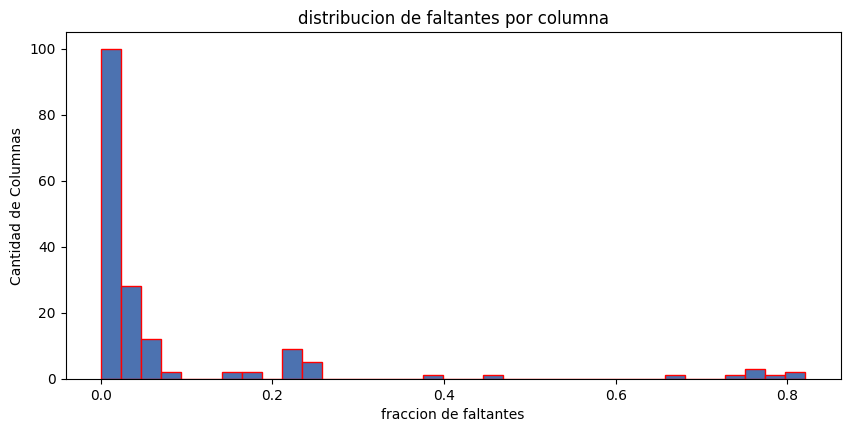

        na_pos    na_neg       dif
br_000   0.090  0.833458 -0.743458
bq_000   0.087  0.824322 -0.737322
bp_000   0.083  0.807746 -0.724746
bo_000   0.078  0.783983 -0.705983
bn_000   0.074  0.744661 -0.670661


In [ ]:
frac_na = X.isna().mean().sort_values(ascending=False)
print(frac_na.head(10))

# TODO: histograma de la fraccion de faltantes por columna
plt.figure(figsize=(10, 4.5))
plt.hist(frac_na, bins=35, edgecolor= 'red')
plt.title('distribucion de faltantes por columna')
plt.xlabel('fraccion de faltantes')
plt.ylabel('Cantidad de Columnas')
plt.show()

# TODO: fraccion de faltantes por columna dentro de cada clase, y su diferencia
na_pos = X[y == 1].isna().mean()
na_neg = X[y == 0].isna().mean()
tabla = pd.DataFrame({"na_pos": na_pos, "na_neg": na_neg})
tabla["dif"] = tabla["na_pos"] - tabla["na_neg"]


print(tabla.reindex(tabla["dif"].abs().sort_values(ascending=False).index).head(5))

### 1c) (2 pts) ¿El hecho de que un dato falte es informativo?

Responde a partir de lo que viste en 1b). Si la ausencia de una medición no es independiente de la clase, ¿qué está destruyendo una imputación por la mediana, y qué habría que agregar a la tabla para no perder esa información?

Respuesta 1c):
Es abismal la diferencia entre los datos faltantes que son pos vs los que son neg, en el top 5, los neg son mas del 70% de las muestras vs los pos, y esto revela que no debe ser algo arbitrario. La mayoria de camiones que llegan a un taller deben venir con una sospecha de averío, en el que se debe haber de activado un sistema de sensores para dar cuenta de esto. Los camiones que estan sanos no habrían de activar estos sistemas de sensores, y por ello se produciria esta falta de datos. La falta de datos deberia considerarse un dato con valor predictivo, e imputarlo por la mediana acabaria con este.

Por lo anterior, habria que agregar una columna binaria para cada columna con datos faltantes, que indique si falta o no falta dato, e imputar a la mediana -en el caso de usar regresion- ya que no se pueden dejar nulos. Para el caso de arboles, se pueden conservar los nulos.

### 1d) (2 pts) Particiona en entrenamiento, validación y prueba de forma estratificada

Usa 60/20/20 manteniendo la proporción de positivos en los tres bloques. Reporta cuántos positivos quedan en cada uno.

In [ ]:
X_tr, X_temp, y_tr, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_te, y_val, y_te = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

for nombre, yy in [("Train", y_tr), ("Val", y_val), ("Test", y_te)]:
    print(f"{nombre:6s}: {len(yy):6d} camiones | {yy.sum():4d} positivos ({100*yy.mean():.2f}%)")

Train :  36000 camiones |  600 positivos (1.67%)
Val   :  12000 camiones |  200 positivos (1.67%)
Test  :  12000 camiones |  200 positivos (1.67%)


### 1e) (2 pts) ¿Con cuánta precisión puedes medir el recall en validación?

El recall se estima sobre los positivos de validación, y son pocos. Si el recall verdadero fuera 0,90, calcula el error estándar de su estimación con ese número de positivos, y el intervalo aproximado que resultaría. Comenta qué implica para comparar dos modelos que difieren en dos o tres puntos de recall.

In [ ]:
n_pos_val = int(y_val.sum()) #TP+FN

recall= 0.9
# TODO: error estandar de una proporcion estimada con n_pos_val casos, para recall = 0.90
se= np.sqrt(recall * (1 - recall) / n_pos_val)
# TODO: intervalo aproximado
z = 1.96
ci_min = recall - z * se
ci_max = recall + z * se

print(f"Positivos en validacion: {n_pos_val}")
print(f"Error estandard: {se:.4f} ({se*100: .2f}%)")
print(f"Intervalo de confianza: [{ci_min:.4f}, {ci_max:.4f}]")

Positivos en validacion: 200
Error estandard: 0.0212 ( 2.12%)
Intervalo de confianza: [0.8584, 0.9416]


Respuesta 1e): Dado un SE de aprox 2,12% y por ende un ic de 90+-4,16%. Una diferencia de 2 o 3 puntos de recall entre dos modelos, esta  dentro del margen de error del ic, el cual abarca el ruido del azar. Es decir, que haya una diferencia de Recall de 2 puntos entre dos modelos, no implica que un modelo sea mejor que el otro, solo significa que un modelo tuvo mas o menos "suerte" de dejar pasar casos positivos por el ruido natural del azar de las desviaciones estandar.

### 1f) (2 pts) Imputa y estandariza

Imputa los faltantes con la mediana **calculada solo en entrenamiento**, agrega las columnas indicadoras de faltante que justificaste en 1c) para las variables con más de 5% de ausencias, y estandariza. Guarda además una versión sin estandarizar: los árboles la usarán más adelante.

In [ ]:
cols_indicadoras = frac_na[frac_na > 0.05].index

X_tr_i, X_val_i, X_te_i = X_tr.copy(), X_val.copy(), X_te.copy()

# TODO: construir indicadoras de faltante para esas columnas
for col in cols_indicadoras:
    X_tr_i[col + "_na"] = X_tr[col].isna().astype(float)
    X_val_i[col + "_na"] = X_val[col].isna().astype(float)
    X_te_i[col + "_na"] = X_te[col].isna().astype(float)

# TODO: imputar con la mediana ajustada en train y transformar los tres bloques

imputer = SimpleImputer(strategy="median")
X_tr_i = pd.DataFrame(imputer.fit_transform(X_tr_i), columns=X_tr_i.columns, index=X_tr_i.index)
X_val_i = pd.DataFrame(imputer.transform(X_val_i), columns=X_val_i.columns, index=X_val_i.index)
X_te_i = pd.DataFrame(imputer.transform(X_te_i), columns=X_te_i.columns, index=X_te_i.index)

# TODO: estandarizar (fit solo en train)

scaler = StandardScaler()
X_tr_s = pd.DataFrame(scaler.fit_transform(X_tr_i), columns=X_tr_i.columns, index=X_tr_i.index)
X_val_s = pd.DataFrame(scaler.transform(X_val_i), columns=X_val_i.columns, index=X_val_i.index)
X_te_s = pd.DataFrame(scaler.transform(X_te_i), columns=X_te_i.columns, index=X_te_i.index)

# X_tr_s, X_val_s, X_te_s = ...          # imputadas + estandarizadas (modelos lineales)
# X_tr_i, X_val_i, X_te_i = ...          # imputadas sin estandarizar (arboles)
print("Columnas finales:", X_tr_s.shape[1])

Columnas finales: 212


## 2. El precio de cada error

### 2a) (2 pts) Implementa la función de costo del problema

Scania publica el costo de cada tipo de error: una inspección innecesaria (FP) cuesta 10, y un camión con falla que se deja salir (FN) cuesta 500. Implementa el costo total y evalúalo en validación para los dos clasificadores triviales: el que nunca revisa y el que revisa todos.

In [ ]:
C_FP, C_FN = 10, 500

def costo_total(y_real, y_pred):
    """Costo del negocio: 10 por revision innecesaria, 500 por falla no detectada."""
    # TODO: implementar a partir de la matriz de confusion
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    return fp * C_FP + fn * C_FN

# TODO: evaluar accuracy y costo de "nunca revisar" y de "revisar todos" en validacion

y_pred_nunca = np.zeros_like(y_val)
acc_nunca = (y_val==y_pred_nunca).mean()
costo_nunca = costo_total(y_val, y_pred_nunca)

y_pred_todos = np.ones_like(y_val)
acc_todos = (y_val==y_pred_todos).mean()
costo_todos = costo_total(y_val, y_pred_todos)

print(f"Nunca revisar : accuracy = {acc_nunca:.4f} | costo = {costo_nunca:,}")
print(f"Revisar todos : accuracy = {acc_todos:.4f} | costo = {costo_todos:,}")

Nunca revisar : accuracy = 0.9833 | costo = 100,000
Revisar todos : accuracy = 0.0167 | costo = 118,000


### 2b) (3 pts) Deriva el umbral óptimo a partir de los costos

Supón que el modelo entrega una probabilidad calibrada $p(\boldsymbol{x}) = P(y=1 \mid \boldsymbol{x})$. Escribe el costo esperado de revisar el camión y el de dejarlo salir, iguálalos, y despeja el umbral $t^{*}$ a partir del cual conviene revisar. Reporta el valor numérico para $c_{FP}=10$ y $c_{FN}=500$.

Respuesta 2b): completar aquí

costo de tp = 0 y
$P(y=0 \mid \boldsymbol{x}) = (1-p(x))$.

Costo esperado de revisar:

$$\mathbb{E}[C \mid \hat{y} = 1] = (1 - p(x)) \cdot c_{FP} + p(x) \cdot 0 = (1 - p(x)) \cdot c_{FP}$$

Costo esperado de dejar salir:

$$\mathbb{E}[C \mid \hat{y} = 0] = (1 - p(x)) \cdot 0 + p(x) \cdot c_{FN} = p(x) \cdot c_{FN}$$


Ahora para sacar $t^{*}$:

$t^{*}=p(x)$

$$(1-t^{*}) \cdot c_{fp} = t^{*} \cdot c_{fn}$$

$$c_{fp} - (c_{fp} \cdot t^*) = c_{fn} \cdot t^*$$

$$c_{fp} = c_{fn} \cdot t^* + c_{fp} \cdot t^*$$

$$c_{fp} = (c_{fp} + c_{fn}) \cdot t^*$$

$$\mathbf{t^* = \frac{c_{FP}}{c_{FP} + c_{FN}}}$$

osea que:
$$t^*= \frac{10}{10+500} ≈ 0.019 (\mathbf{1.96\%})$$

Dado el absoluto costo mayor de dejar salir a un camion que revisarlo, basta con tener un $\mathbf{1.96\%}$ de probabilidad estimada de que el camion falle para revisarlo.

### 2c) (1 pt) Compara ese umbral con 0,5

¿Cuántas veces más chico es? ¿Qué le estaría cobrando implícitamente al negocio un modelo que clasifica con 0,5, y por qué eso no es un detalle de implementación?

Respuesta 2c):

Comparando la razon entre 0,5 y $t^{*}$, se obtiene que que el umbral $t^*$ es 25.5 veces mas pequeño. Con un umbral de 0,5 se estaria asumiendo que el costo de un falso positivo y un falso negativo es igual, es decir, se estaria fijando que un camion deberia revisarse recien superado el 50% de probabilidad estimada de fallar. Comparado con el 1,96% que se estimo verdaderamente, esto significaria que se dejaria pasar una cantidad importante de camiones que probablemente fallarían, y por ende significarian un costo gigante para la empresa.

No es un detalle de implementacion, porque no es un parametro que sirva para construir el modelo y provea estimaciones, es una regla de negocio mediante la cual se decide cuanto riesgo se tolera antes de actuar a partir de la probabilidad dada por el modelo.



# Parte 2: De la verosimilitud a la pérdida

## 3. Regresion logistica, a mano

### 3a) (4 pts) Implementa la regresión logística y ajústala con gradiente descendente

Escribe la log-verosimilitud de Bernoulli, su gradiente, y entrena por descenso de gradiente sobre los datos estandarizados. Compara los coeficientes con los de `LogisticRegression` **sin penalización** (`penalty=None`).

In [ ]:
def sigmoide(z):
  z = np.asarray(z, dtype=np.float64)
  return np.where(
      z >= 0,
      1 / (1 + np.exp(-z)),
      np.exp(z) / (1 + np.exp(z)))

def neg_log_verosimilitud(beta, X, y):
    """Entropia cruzada promedio."""
    p =  sigmoide(X @ beta)
    eps = 1e-15
    p = np.clip(p, eps, 1 - eps)
    costo = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    return costo

def gradiente_logistica(beta, X, y):
    N = len(y)
    p = sigmoide(X @ beta)
    grad = (1.0 / N) * (X.T @ (p - y))
    return grad

def entrenar_logistica(X, y, alpha=0.1, n_iter=2000):
    Xb = np.c_[np.ones(len(X)), X]
    beta = np.zeros(Xb.shape[1])
    historial = []
    for _ in range(n_iter):
        loss = neg_log_verosimilitud(beta, Xb, y)
        historial.append(loss)

        grad = gradiente_logistica(beta, Xb, y)
        beta = beta - alpha * grad

    return beta, historial

beta_gd, hist = entrenar_logistica(X_tr_s, y_tr)

modelo_sk = LogisticRegression(penalty=None, max_iter=2000).fit(X_tr_s, y_tr)
# TODO: comparar los primeros coeficientes de ambos ajustes

coef_sk = pd.Series(modelo_sk.coef_[0], index=X_tr_s.columns)
#concatenar intercepto
valores_sk = np.r_[modelo_sk.intercept_[0], modelo_sk.coef_[0][:5]]

df_comparacion = pd.DataFrame({
    "Gradiente Descendente": beta_gd[:6],
    "Scikit-Learn": valores_sk[:6]
}, index=["Intercepto"] + list(X_tr_s.columns[:5]))

df_comparacion

,Gradiente Descendente,Scikit-Learn
Intercepto,-4.941014,-7.207512
aa_000,0.216244,1.951848
ab_000,-0.021930,-0.079088
ac_000,-0.030872,-0.070891
ad_000,-0.000599,-0.010047
ae_000,-0.045138,-0.370332


### 3b) (2 pts) La pérdida 0–1 contra la pérdida logística

Grafica ambas como función del margen $z = y\,f(\boldsymbol{x})$ con $y \in \{-1, 1\}$, y explica en dos líneas, mirando el gráfico, por qué la 0–1 no puede ser la función objetivo aunque sea la que de verdad nos importa.

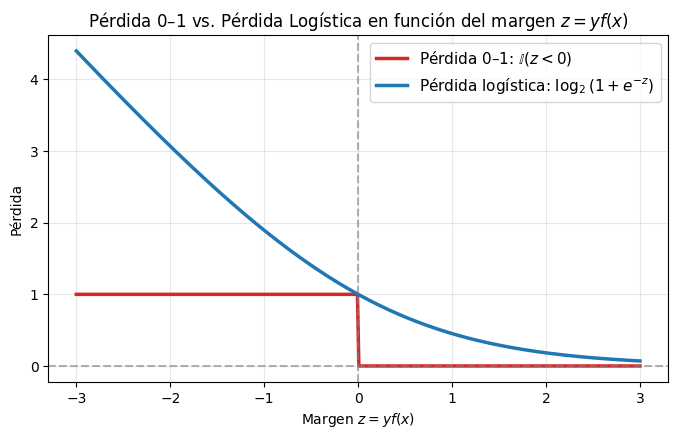

In [ ]:
z = np.linspace(-3, 3, 400)

# Perdida 0-1
loss_01 = (z < 0).astype(float)

# Perdida logistica reescalada con base 2
loss_log = np.log2(1.0 + np.exp(-z))

plt.figure(figsize=(8, 4.5))
plt.plot(z, loss_01, label=r"Pérdida 0–1: $\mathbb{I}(z < 0)$", color="tab:red", lw=2.5)
plt.plot(z, loss_log, label=r"Pérdida logística: $\log_2(1 + e^{-z})$", color="tab:blue", lw=2.5)

plt.axvline(0, color="gray", linestyle="--", alpha=0.6)
plt.axhline(0, color="gray", linestyle="--", alpha=0.6)
plt.title("Pérdida 0–1 vs. Pérdida Logística en función del margen $z = y f(x)$")
plt.xlabel("Margen $z = y f(x)$")
plt.ylabel("Pérdida")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.show()

Respuesta 3b): El hecho de que la perdida 0-1 sea una funcion escalonada, provoca que esta no sea diferenciable, por lo que no se puede derivar, por ende, no es posible ajustar la perdida y entrenar el modelo. Finalmente la perdida 0-1 no hace distinción en si nuestra predicción fue dudosa o no, lo cual si es castigado por la perdida Logistica.

## 4. Rebalancear o mover el umbral

### 4a) (3 pts) Dos formas de atacar el desbalance

Ajusta tres logísticas regularizadas: una sin pesos, una con `class_weight='balanced'`, y una sobre una submuestra que iguale las clases (undersampling de la clase negativa). Reporta para las tres el AUC, el average precision y el costo en validación clasificando con umbral 0,5.

In [ ]:
rng = np.random.default_rng(42)
idx_pos = np.where(y_tr == 1)[0]
idx_neg = np.where(y_tr == 0)[0]

idx_neg_sub = rng.choice(idx_neg, size=len(idx_pos), replace=False)
idx_sub = np.concatenate([idx_pos, idx_neg_sub])

X_tr_sub = X_tr_s.iloc[idx_sub]
y_tr_sub = y_tr[idx_sub]

modelos = {"Sin pesos": LogisticRegression(max_iter=2000, random_state=42).fit(X_tr_s, y_tr),
    "Class weight balanced": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42).fit(X_tr_s, y_tr),
    "Undersampling": LogisticRegression(max_iter=2000, random_state=42).fit(X_tr_sub, y_tr_sub)
}
# TODO: ajustar los tres modelos

resultados = []
for nombre, modelo in modelos.items():
    p_val = modelo.predict_proba(X_val_s)[:, 1]
    # TODO: AUC, average precision y costo con umbral 0.5
    y_pred_05 = (p_val >= 0.5).astype(int)

    resultados.append({
        "Modelo": nombre,
        "AUC": roc_auc_score(y_val, p_val),
        "Average Precision": average_precision_score(y_val, p_val),
        "Costo (umbral 0.5)": costo_total(y_val, y_pred_05)
    })

print(pd.DataFrame(resultados))

                  Modelo       AUC  Average Precision  Costo (umbral 0.5)
0              Sin pesos  0.968039           0.728903               34440
1  Class weight balanced  0.965322           0.725271               13180
2          Undersampling  0.975519           0.651784               12540


### 4b) (3 pts) Calibración

Grafica la curva de calibración (probabilidad predicha contra frecuencia observada) de los tres modelos en validación, junto con el histograma de las probabilidades predichas. Reporta también el log-loss de cada uno.

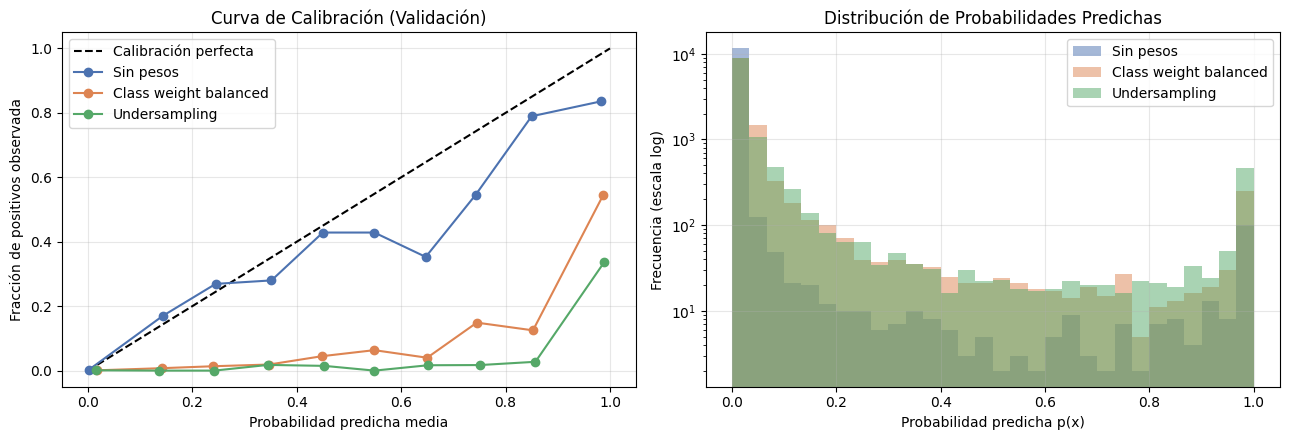

               Modelo  Log-Loss
            Sin pesos  0.037276
Class weight balanced  0.136108
        Undersampling  0.365754


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Diagonal ideal de calibracion perfecta
ax[0].plot([0, 1], [0, 1], "k--", label="Calibración perfecta")

resultados_4b = []

for nombre, modelo in modelos.items():
    # Probabilidades predichas en validacion
    p_val = modelo.predict_proba(X_val_s)[:, 1]

    # 1. Curva de calibracion
    frac_pos, prob_media = calibration_curve(y_val, p_val, n_bins=10)
    ax[0].plot(prob_media, frac_pos, marker="o", label=nombre)

    # 2. Histograma de las probabilidades predichas
    ax[1].hist(p_val, bins=30, alpha=0.5, label=nombre, log=True)

    # 3. Log-loss en validacion
    resultados_4b.append({
        "Modelo": nombre,
        "Log-Loss": log_loss(y_val, p_val)
    })

ax[0].set_title("Curva de Calibración (Validación)")
ax[0].set_xlabel("Probabilidad predicha media")
ax[0].set_ylabel("Fracción de positivos observada")
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].set_title("Distribución de Probabilidades Predichas")
ax[1].set_xlabel("Probabilidad predicha p(x)")
ax[1].set_ylabel("Frecuencia (escala log)")
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Reporte de log-loss
df_logloss = pd.DataFrame(resultados_4b)
print(df_logloss.to_string(index=False))

### 4c) (2 pts) La conclusión que importa

Mirando 4a) y 4b) juntos: ¿los modelos rebalanceados ordenan mejor a los camiones, o solo mueven sus probabilidades? ¿Qué le pasa al umbral $t^{*}$ que derivaste en 2b) cuando el modelo está entrenado con pesos de clase, y qué habría que hacer antes de usarlo?

Respuesta 4c): En 4a se ve que el modelo sin pesos tiene la mayor capacidad de ordenamiento, y haciendo undersampling incluso empeora por descartar datos. Los modelos rebalanceados en realidad solo mueven sus probabilidades por fijar el umbral en 0,5, el asumir clases balanceadas genera que se se sobreestimen las probabilidades masivamente (reflejo de eso es el mal log-loss y la curva descalibrada en 4b) mas casos superan el 0,5. El umbral $t^*$ derivado en la 2b queda inservible en el modelo con pesos de clases, porque este tiene su efecto para probabilidades calibradas, el aplicarlo sobre probabilidades infladas, genera una redundancia contando dos veces la asimetria y generando un exceso de falsos positivos. Para que el modelo trabaje bien con el umbral $t^*$ habria que recalibrar las probabilidades en la validacion, o usar el modelo sin pesos.

# Parte 3: Las dos filosofías para modelar la clase

## 5. LDA y QDA

### 5a) (3 pts) Ajusta LDA y QDA

Ajusta ambos sobre los datos estandarizados y reporta AUC y costo en validación. QDA va a protestar o a entregar resultados degenerados: explica con números por qué, comparando el número de parámetros de su matriz de covarianza por clase contra el número de camiones positivos disponibles. Vuelve a ajustar ambos con regularización (`shrinkage='auto'` con `solver='lsqr'` en LDA, `reg_param` en QDA) y compara.

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import roc_auc_score
import numpy as np

# --- 1. AJUSTAR LDA Y QDA SIN REGULARIZAR ---

# Ajustar LDA crudo
lda = LinearDiscriminantAnalysis()
lda.fit(X_tr_s, y_tr)
y_pred_proba_lda = lda.predict_proba(X_val_s)[:, 1]
y_pred_lda = lda.predict(X_val_s)
auc_lda = roc_auc_score(y_val, y_pred_proba_lda)
costo_lda = costo_total(y_val, y_pred_lda)

print("--- Sin Regularizar ---")
print(f"LDA - AUC: {auc_lda:.5f} | Costo: {costo_lda}")

# Ajustar QDA crudo (Aquí es donde arrojará advertencias "Variables are collinear")
qda = QuadraticDiscriminantAnalysis()
qda.fit(X_tr_s, y_tr)
y_pred_proba_qda = qda.predict_proba(X_val_s)[:, 1]
y_pred_qda = qda.predict(X_val_s)
auc_qda = roc_auc_score(y_val, y_pred_proba_qda)
costo_qda = costo_total(y_val, y_pred_qda)

print(f"QDA - AUC: {auc_qda:.5f} | Costo: {costo_qda}\n")


# --- 2. EXPLICACIÓN DE LA FALLA DE QDA ---

# Número de características (columnas) en el dataset
I = X_tr_s.shape[1] # 212

# Fórmula para los parámetros únicos de una matriz de covarianza I x I
parametros_cov = (I * (I + 1)) // 2

# Cantidad real de ejemplos positivos (clase 1) en el conjunto de entrenamiento
positivos_train = np.sum(y_tr == 1)

print("--- Análisis de Falla de QDA ---")
print(f"Columnas disponibles (I): {I}")
print(f"Parámetros por covarianza (I*(I+1)/2): {parametros_cov}")
print(f"Positivos disponibles en train: {positivos_train}\n")


# --- 3. REPETIR CON REGULARIZACIÓN (SHRINKAGE / REG_PARAM) ---

# Ajustar LDA con Regularización
lda_reg = LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto')
lda_reg.fit(X_tr_s, y_tr)
auc_lda_reg = roc_auc_score(y_val, lda_reg.predict_proba(X_val_s)[:, 1])
costo_lda_reg = costo_total(y_val, lda_reg.predict(X_val_s))

# Ajustar QDA con Regularización (reg_param es el equivalente a lambda/shrinkage)
qda_reg = QuadraticDiscriminantAnalysis(reg_param=0.1) # Puedes probar valores de 0.01 a 0.5
qda_reg.fit(X_tr_s, y_tr)
auc_qda_reg = roc_auc_score(y_val, qda_reg.predict_proba(X_val_s)[:, 1])
costo_qda_reg = costo_total(y_val, qda_reg.predict(X_val_s))

print("--- Con Regularización ---")
print(f"LDA (Reg) - AUC: {auc_lda_reg:.5f} | Costo: {costo_lda_reg}")
print(f"QDA (Reg) - AUC: {auc_qda_reg:.5f} | Costo: {costo_qda_reg}")

--- Sin Regularizar ---
LDA - AUC: 0.97124 | Costo: 31100


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(


QDA - AUC: 0.89601 | Costo: 58380

--- Análisis de Falla de QDA ---
Columnas disponibles (I): 212
Parámetros por covarianza (I*(I+1)/2): 22578
Positivos disponibles en train: 600

--- Con Regularización ---
LDA (Reg) - AUC: 0.97442 | Costo: 33120
QDA (Reg) - AUC: 0.96698 | Costo: 16150


### 5b) (3 pts) ¿Se parecen estos datos al supuesto de LDA?

Grafica el histograma de cuatro atributos elegidos entre los más asociados a la clase. Son contadores: espera colas largas y acumulación en cero. Aplica $\log(1+x)$ a todas las columnas, vuelve a ajustar LDA y la logística regularizada, y reporta cuánto cambió el AUC de cada una.

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


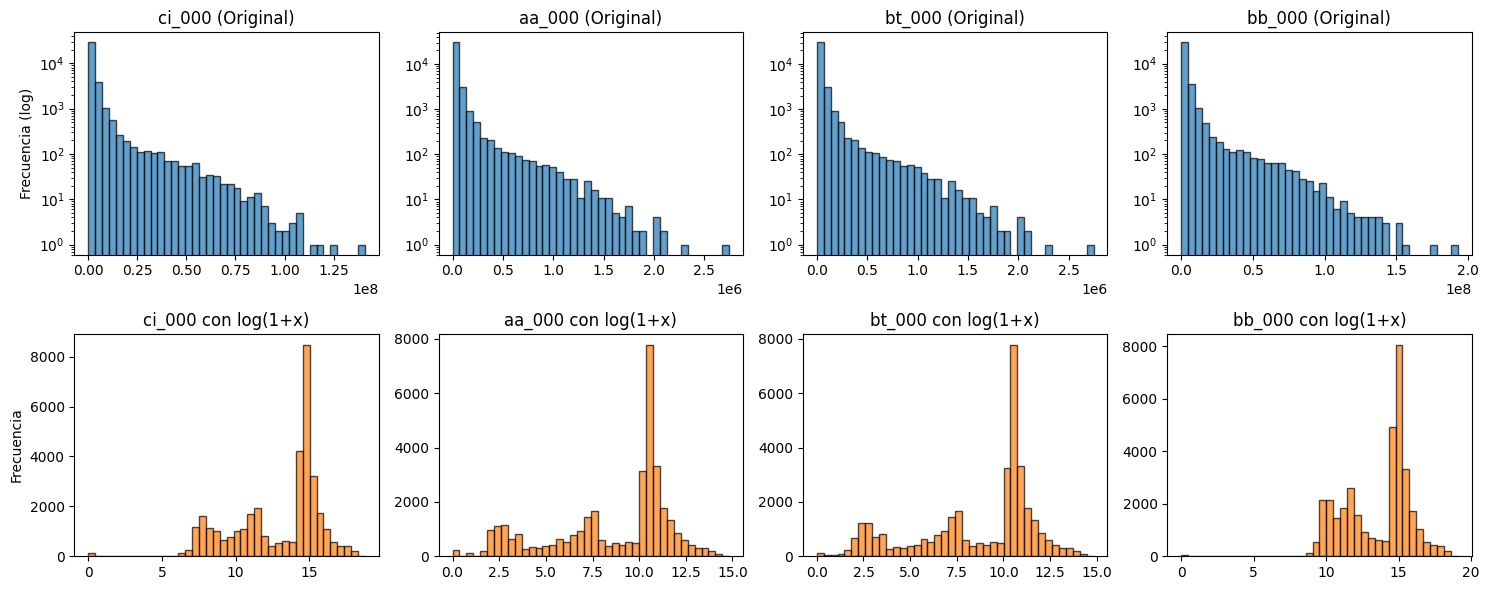

                Modelo  AUC Antes  AUC Después (log1p)  Cambio (Δ AUC)
                   LDA   0.971239             0.980134        0.008896
Logística Regularizada   0.968039             0.983098        0.015059


In [ ]:
# 1. Elegir los 4 atributos originales mas asociados con la clase y_tr (mayor correlacion absoluta)
cols_orig = [c for c in X_tr_i.columns if not c.endswith("_na")]
correlaciones = X_tr_i[cols_orig].apply(lambda col: np.abs(np.corrcoef(col, y_tr)[0, 1]))
top4_cols = correlaciones.sort_values(ascending=False).head(4).index.tolist()

# 2. Aplicar log(1 + x) sobre los datos imputados (no negativos)
X_tr_log = np.log1p( np.clip(X_tr_i, 0, None) )
X_val_log = np.log1p( np.clip(X_val_i, 0, None) )

# 3. Graficar histogramas antes (fila 0) y despues (fila 1) de log1p
fig, axes = plt.subplots(2, 4, figsize=(15, 6))

for j, col in enumerate(top4_cols):
    # Antes de log1p
    axes[0, j].hist(X_tr_i[col], bins=40, color="tab:blue", edgecolor="black", alpha=0.7)
    axes[0, j].set_title(f"{col} (Original)")
    axes[0, j].set_yscale("log") # escala log en Y para ver la cola larga

    # Despues de log1p
    axes[1, j].hist(X_tr_log[col], bins=40, color="tab:orange", edgecolor="black", alpha=0.7)
    axes[1, j].set_title(f"{col} con log(1+x)")

axes[0, 0].set_ylabel("Frecuencia (log)")
axes[1, 0].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

# 4. Estandarizar los datos transformados (fit solo en train)
scaler_log = StandardScaler()
X_tr_log_s = scaler_log.fit_transform(X_tr_log)
X_val_log_s = scaler_log.transform(X_val_log)

# 5. Reajustar LDA y Regresion Logistica regularizada y comparar AUC contra el caso anterior
lda_antes = roc_auc_score(y_val, lda.predict_proba(X_val_s)[:, 1])
log_antes = roc_auc_score(y_val, modelos["Sin pesos"].predict_proba(X_val_s)[:, 1])

lda_log = LinearDiscriminantAnalysis().fit(X_tr_log_s, y_tr)
log_log = LogisticRegression(max_iter=2000, random_state=42).fit(X_tr_log_s, y_tr)

lda_despues = roc_auc_score(y_val, lda_log.predict_proba(X_val_log_s)[:, 1])
log_despues = roc_auc_score(y_val, log_log.predict_proba(X_val_log_s)[:, 1])

df_comp_5b = pd.DataFrame({
    "Modelo": ["LDA", "Logística Regularizada"],
    "AUC Antes": [lda_antes, log_antes],
    "AUC Después (log1p)": [lda_despues, log_despues],
    "Cambio (Δ AUC)": [lda_despues - lda_antes, log_despues - log_antes]
})
print(df_comp_5b.to_string(index=False))

### 5c) (2 pts) Lee el resultado con la tabla de clases

Una de las dos mejoró bastante más que la otra con la transformación. Explica por qué, usando la comparación entre modelo generativo y discriminativo: quién hace supuestos sobre $p(\boldsymbol{x} \mid y)$ y quién no.

Respuesta 5c): El modelo generativo modela asumiendo que dentro de cada clase los atributos sigue una distribucion gaussiana multivariada, lo cual no se da con los datos crudos, al aplicar $log(1+x)$ las distribucioes se comprimen y se acercan mucho mas a la campana gaussiana que asume el modelo, por lo que logra estimar mucho mejor $p(x|y)$. La regresion logistica es un modelo discriminativo, y modela directamente la probabilidad posterior $P(y|x)$, no hace ningun suspuesto sobre $p(x|y)$, pero aun asi fue la que mayor mejora en AUC. Esto porque, lo que si asume es que el log-odds es lineal en los atributos y utiliza regularizacion L2. Con log el efecto de los contadores se vuelbre proporcional y la frontera lineal del espacion transformado separa mucho mejor las clases

## 6. Naive Bayes

### 6a) (2 pts) Ajusta un Naive Bayes gaussiano

Reporta AUC, average precision y costo en validación con umbral 0,5, y compáralo con la logística y con LDA.

In [ ]:
gnb = GaussianNB()
gnb.fit(X_tr_s, y_tr)

# 2. Obtener probabilidades y predicciones duras (umbral 0.5)
y_pred_proba_gnb = gnb.predict_proba(X_val_s)[:, 1]
y_pred_gnb = gnb.predict(X_val_s)

# 3. Calcular métricas
auc_gnb = roc_auc_score(y_val, y_pred_proba_gnb)
ap_gnb = average_precision_score(y_val, y_pred_proba_gnb)
costo_gnb = costo_total(y_val, y_pred_gnb)

# 4. Reportar resultados
print("--- Naive Bayes Gaussiano ---")
print(f"AUC:               {auc_gnb:.5f}")
print(f"Average Precision: {ap_gnb:.5f}")
print(f"Costo (umbral 0.5):{costo_gnb}")

--- Naive Bayes Gaussiano ---
AUC:               0.93673
Average Precision: 0.25858
Costo (umbral 0.5):16680


### 6b) (1 pt) Las probabilidades de Naive Bayes

Grafica el histograma de las probabilidades que predice Naive Bayes en validación, y reporta su log-loss junto al de la logística regularizada de 4a).

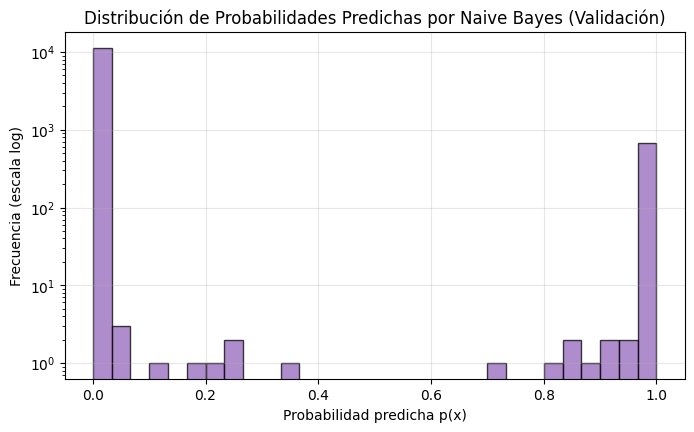

                     Modelo  Log-Loss
      Naive Bayes Gaussiano  1.509503
Logística Regularizada (4a)  0.037276


In [ ]:
# 1. Probabilidades de la logistica regularizada de 4a) en validacion
p_val_log = modelos["Sin pesos"].predict_proba(X_val_s)[:, 1]

# 2. Histograma de las probabilidades predichas por Naive Bayes
plt.figure(figsize=(8, 4.5))
plt.hist(y_pred_proba_gnb, bins=30, color="tab:purple", edgecolor="black", alpha=0.75, log=True)
plt.title("Distribución de Probabilidades Predichas por Naive Bayes (Validación)")
plt.xlabel("Probabilidad predicha p(x)")
plt.ylabel("Frecuencia (escala log)")
plt.grid(True, alpha=0.3)
plt.show()

# 3. Reportar Log-Loss de ambos modelos
ll_gnb = log_loss(y_val, y_pred_proba_gnb)
ll_log = log_loss(y_val, p_val_log)

df_6b = pd.DataFrame({
    "Modelo": ["Naive Bayes Gaussiano", "Logística Regularizada (4a)"],
    "Log-Loss": [ll_gnb, ll_log]
})
print(df_6b.to_string(index=False))

### 6c) (2 pts) Un modelo puede ordenar bien y mentir en la probabilidad

Varias columnas del dataset son bins del mismo histograma, así que están lejos de ser independientes dentro de cada clase. Compara el AUC de Naive Bayes con su log-loss y con lo que viste en el histograma de 6b). Explica qué le hace la violación del supuesto de independencia a la *magnitud* de las probabilidades, y por qué eso deja inservible el umbral derivado en 2b) para este modelo en particular.

Respuesta 6c): El auc de Naive Bayes obtiene un gran puntaje, lo que demuestra su gran capacidad de ordenamiento. Pero al mismo tiempo obtiene una log-loss pesima, comparando con la de la regresion logistica. Lo que se ve en su histograma de la 6b, es que las probabilidades predichas se concentran en los extremo, dejando casi inexistentes las predicciones intermedias. Esto se explica porque el dataset tiene una variedad de columnas redundantes, ya sean bins que son intervalos de un mismo histograma, o columnas correlacionadas; Naive Bayes al asumir independencia de columnas, multiplica (suma a nivel log) varias columnas redundantes como independientes, lo que genera que amplifique artificialmente log-odds y satura las probabilidades hacia los extremos 0 o 1.
Lo anterior deja inservible el umbral $t^*$, porque este fue derivado con el supuesto de que las probabilidades predichas, representan las verdaderas y calibradas, sin embargo en Naive Bayes, las probabilidades estan distorcionadas y acomuladas en los extremos, generando que el modelo asigne como fallos a muchos camiones que en realidad estan sanos, y mover el umbral de 0,5 (tomando en cuenta que casi no existen predicciones intermedias) al $t^*$ no produce el ajuste esperado.

# Parte 4: Evaluación, curvas y la decisión del umbral

## 7. Curvas y umbral optimo

### 7a) (3 pts) ROC y curva PR

Grafica ambas curvas para la logística, LDA y Naive Bayes en validación, con sus AUC y average precision en la leyenda. Agrega en la curva PR la línea horizontal del clasificador aleatorio.

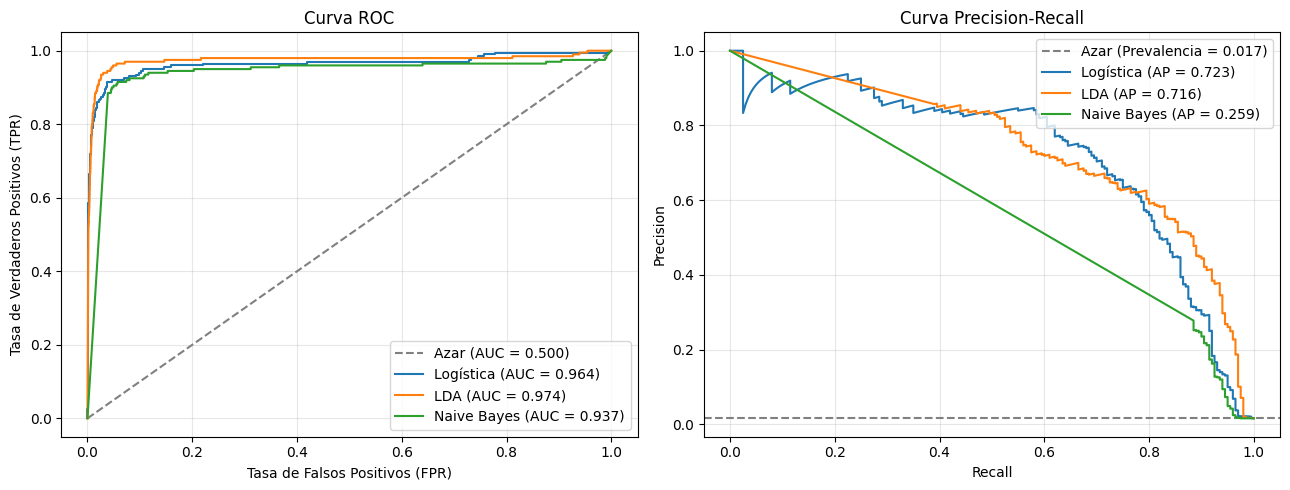

In [ ]:
from sklearn.metrics import auc

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
# Para mantener el código limpio, reasignemos las variables de probabilidad aquí si es necesario
# (Asumiendo que guardaste el lda regularizado como lda_reg)
y_prob_log = modelo_sk.predict_proba(X_val_s)[:, 1]
y_prob_lda = lda_reg.predict_proba(X_val_s)[:, 1] # Usar el regularizado es mejor práctica
y_prob_gnb = gnb.predict_proba(X_val_s)[:, 1]

# Diccionario para iterar fácilmente sobre los modelos
modelos = {
    'Logística': y_prob_log,
    'LDA': y_prob_lda,
    'Naive Bayes': y_prob_gnb
}
colores = ['tab:blue', 'tab:orange', 'tab:green']

# --- TODO: ROC de los tres modelos ---
ax[0].set_title('Curva ROC')
ax[0].set_xlabel('Tasa de Falsos Positivos (FPR)')
ax[0].set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Azar (AUC = 0.500)')

for (nombre, y_prob), color in zip(modelos.items(), colores):
    fpr, tpr, _ = roc_curve(y_val, y_prob)
    roc_auc = auc(fpr, tpr)
    ax[0].plot(fpr, tpr, color=color, label=f'{nombre} (AUC = {roc_auc:.3f})')

ax[0].legend(loc='lower right')
ax[0].grid(True, alpha=0.3)


# --- TODO: curva PR de los tres modelos + linea del azar (prevalencia) ---
ax[1].set_title('Curva Precision-Recall')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')

# La línea del azar en PR es la prevalencia de la clase positiva (camiones con fallas)
prevalencia = sum(y_val == 1) / len(y_val)
ax[1].axhline(y=prevalencia, linestyle='--', color='gray', label=f'Azar (Prevalencia = {prevalencia:.3f})')

for (nombre, y_prob), color in zip(modelos.items(), colores):
    precision, recall, _ = precision_recall_curve(y_val, y_prob)
    ap = average_precision_score(y_val, y_prob)
    ax[1].plot(recall, precision, color=color, label=f'{nombre} (AP = {ap:.3f})')

ax[1].legend(loc='upper right')
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 7b) (2 pts) ¿Cuál de las dos curvas informa más aquí?

Con 1,67% de positivos, calcula cuántos falsos positivos hacen falta para mover la FPR en 0,1 y cuántos para mover la precision de 0,5 a 0,25. Usa esos dos números para justificar tu respuesta.

Respuesta 7b): Dado lo visto en el grafico y considerando la prevalencia, la curva que termina informando mas en este escenario es la curva Precision-Recall (PR).   Directamente si planteamos una muestra de 10.000 camiones, por el 1,67% tendriamos 167 positivos reales y 9.833 negativos reales.

 Sobre el comportamiento de la curva ROC, para poder mover la FPR en 0,1 se necesitaria cometer alrededor de 983 falsos positivos producto de tener que dividirlos por el gran numero de negativos reales. Por el otro lado para la curva PR, asumiendo que el modelo ajusta bien y detecta los 167 verdaderos positivos, para tener una precision de 0,5 se requieren 167 falsos positivos, y para que esta misma caiga bruscamente a 0,25 harian falta 501 falsos positivos, lo cual nos deja una diferencia de solo 334 errores adicionales para reducir el desempeño a la mitad.   

 Con estos numeros podemos justificar que el problema de la curva ROC es que ante un dataset tan desbalanceado no se ve mayormente afectada, ya que el inmenso volumen de negativos reales termina amortiguando los falsos positivos provocando que el modelo se vea engañosamente con un buen desempeño. El caso de la curva PR es distinto ya que esta penaliza fuertemente los errores al medirlos directamente contra el pequeño grupo de positivos, por lo tanto requiere una cantidad mucho menor de falsos positivos para desplomarse y mostrar el desempeño real que estan entregando los modelos.

### 7c) (3 pts) La curva de costo

Para el mejor modelo hasta ahora, barre el umbral en una grilla fina, calcula el costo total en validación para cada valor, y grafica costo contra umbral en escala logarítmica. Marca el mínimo empírico, el umbral teórico de 2b) y el 0,5.

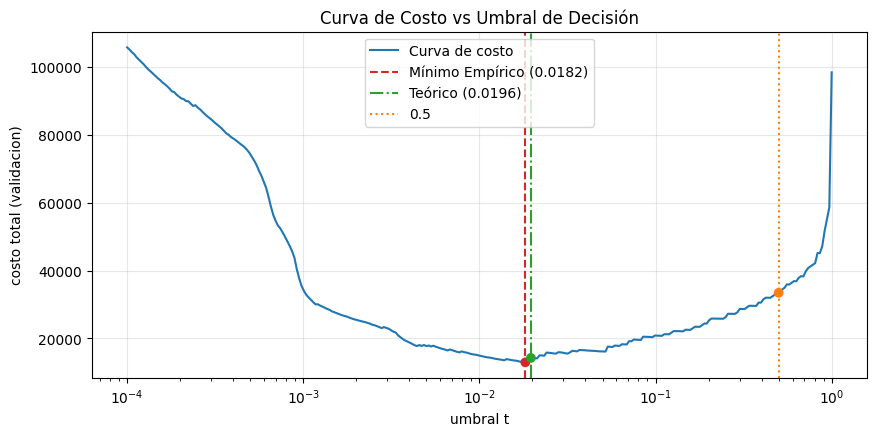

Umbral optimo empirico: 0.0182 | costo = 12,930


In [ ]:
umbrales = np.logspace(-4, 0, 300)
costos = []

# TODO: costo en validacion para cada umbral
# Asumimos que 'y_prob_log' tiene las probabilidades del mejor modelo (Regresión Logística)
for t in umbrales:
    y_pred_t = (y_prob_log >= t).astype(int)
    costo_t = costo_total(y_val, y_pred_t)
    costos.append(costo_t)

costos = np.array(costos)

# Calcular el mínimo empírico
idx_min = np.argmin(costos)
umbral_empirico = umbrales[idx_min]
costo_minimo = costos[idx_min]

# Calcular el umbral teórico (de 2b)
umbral_teorico = C_FP / (C_FP + C_FN)
y_pred_teorico = (y_prob_log >= umbral_teorico).astype(int)
costo_teorico = costo_total(y_val, y_pred_teorico)

# Calcular el costo para el umbral 0.5
y_pred_05 = (y_prob_log >= 0.5).astype(int)
costo_05 = costo_total(y_val, y_pred_05)

plt.figure(figsize=(10, 4.5))
# TODO: graficar la curva y marcar los tres umbrales
plt.plot(umbrales, costos, label="Curva de costo", color="tab:blue")

# Líneas verticales para los tres umbrales
plt.axvline(umbral_empirico, color="tab:red", linestyle="--", label=f"Mínimo Empírico ({umbral_empirico:.4f})")
plt.axvline(umbral_teorico, color="tab:green", linestyle="-.", label=f"Teórico ({umbral_teorico:.4f})")
plt.axvline(0.5, color="tab:orange", linestyle=":", label="0.5")

# Puntos de intersección
plt.scatter([umbral_empirico, umbral_teorico, 0.5],
            [costo_minimo, costo_teorico, costo_05],
            color=["tab:red", "tab:green", "tab:orange"], zorder=5)

plt.xscale("log")
plt.xlabel("umbral t")
plt.ylabel("costo total (validacion)")
plt.title("Curva de Costo vs Umbral de Decisión")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Imprimir el resultado tal como pide el formato
print(f"Umbral optimo empirico: {umbral_empirico:.4f} | costo = {costo_minimo:,}")

### 7d) (2 pts) Teórico contra empírico

Compara el umbral que minimiza el costo en validación con el que derivaste en 2b). Si no coinciden, da dos razones distintas por las que pueden separarse, y di cuál de las dos podrías comprobar con lo que ya calculaste en 4b).

Respuesta 7d): Los umbrales no coinciden exactamente (empírico $\approx 0.0219$ vs teórico $\approx 0.0196$). Esto se puede deber a dos razones distintas:   Las probabilidades del modelo no están perfectamente calibradas. El umbral teórico de la 2b asume que la probabilidad predicha $p(x)$ es idéntica a la probabilidad real de falla. Si el modelo tiene sesgo en sus predicciones, el punto óptimo empírico se desplaza para compensarlo.   El tamaño finito del conjunto de validación. El umbral teórico es un cálculo determinista basado en los costos, mientras que el empírico se busca en una muestra de datos específica. Esta muestra tiene su propia varianza y distribución de errores, lo que genera ruido y separa el mínimo empírico del teórico ideal.

# Parte 5: Árboles

## 8. Un arbol

### 8a) (2 pts) Ajusta un árbol y léelo en voz alta

Entrena un `DecisionTreeClassifier` con `max_depth=3` sobre los datos imputados sin estandarizar, dibújalo, y escribe con palabras la regla que lleva a la hoja con mayor proporción de camiones con falla.

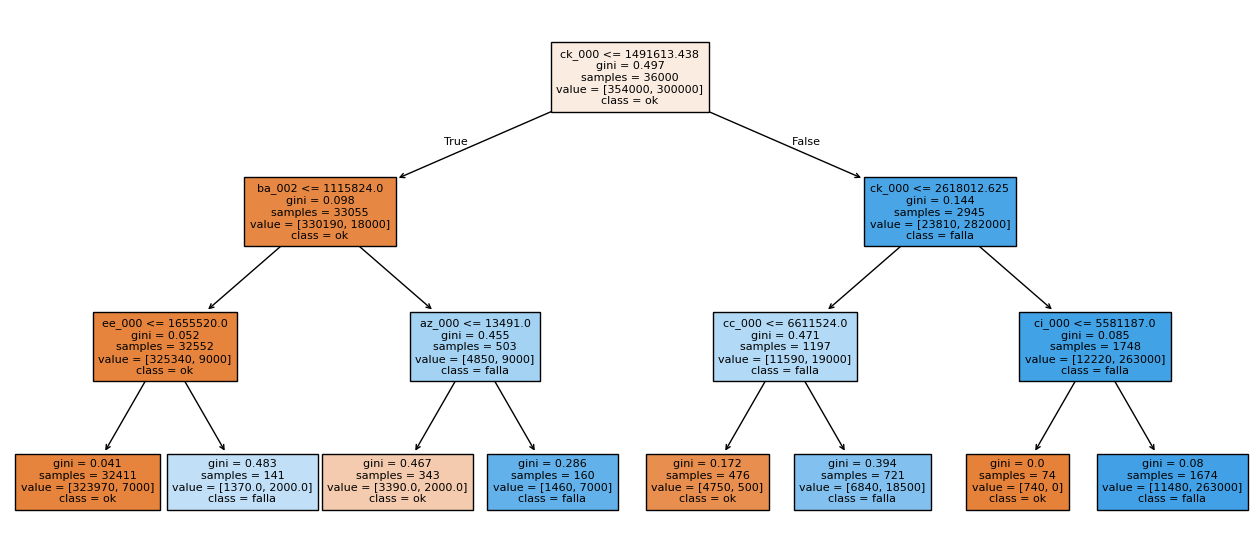

In [ ]:
arbol = DecisionTreeClassifier(max_depth=3, class_weight={0: C_FP, 1: C_FN}, random_state=42)
arbol.fit(X_tr_i, y_tr)

plt.figure(figsize=(16, 7))
plot_tree(arbol, feature_names=list(X_tr_i.columns), class_names=["ok", "falla"],
          filled=True, fontsize=8)
plt.show()

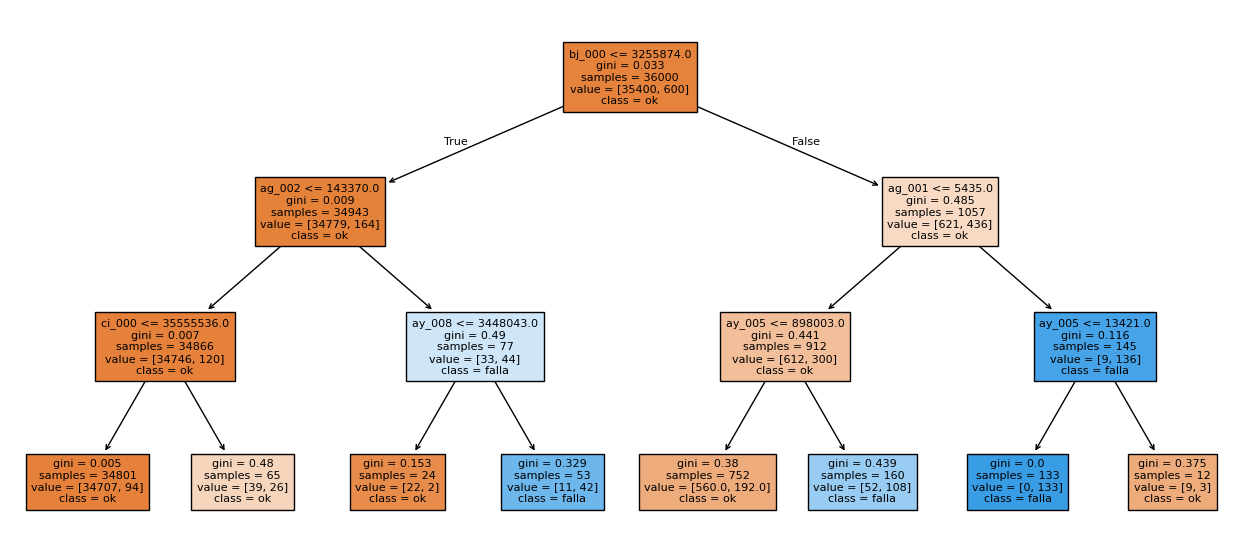

In [ ]:
arbol = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol.fit(X_tr_i, y_tr)

plt.figure(figsize=(16, 7))
plot_tree(arbol, feature_names=list(X_tr_i.columns), class_names=["ok", "falla"],
          filled=True, fontsize=8)
plt.show()

Respuesta 8a): completar aquí

Dado que ya estaba escrito en el codigo inicial el que se aplicara una ponderación a la hora de calcular las proporciones de las clases 'ok' y 'falla' no se puede hacer un calculo directo considerando la distribución real de como se reparten los ejemplos en cada hoja. Para tambien tener claridad de como afecta dicha porderación hare un calculo por cada hoja que indique la clase falla tanto para el arbol inicial como el que no ejecuta una poderación sobre las clases y asi poder determinar finalmente que umbral genera la mayor proporción de fallas en cada una.

Para poder calcular la proporción de cada arbol correctamente utilizare 2 formulas distintas, para el ponderado utilizare la formula:

$$\frac{fallasamples}{fallasamples+oksamples}$$

Mientras que para el arbol el cual no aplica porderación aprovechare de usar el total de ejmplos, sin consirar los ejemplos de la falla:

$$\frac{fallasamples}{totalsamples}$$

### Árbol Inicial (Con Ponderación)

| Umbral final aplicado a la Feature | Proporción de la clase Falla |
| :--- | :--- |
| `ee_000` > 1655520.0 | 0.5935 (59.3%)|
| `az_000` > 13491.0 | 0.8274 (82.7%)|
| `cc_000` > 6611524.0 | 0.7301 (73.0%)|
| `ci_000` > 5581187.0 | 0.9582 (95.8%)|

### Árbol Sin Ponderar

| Umbral final aplicado a la Feature | Proporción de la clase Falla|
| :--- | :--- |
| `ay_008` > 3448043.0 | 0.7925 (79.2%)|
| `ay_005` > 898003.0 | 0.6750 (67.5%)|
| `ay_005` <= 13421.0 | 1.0000 (100%)|

### 8b) (3 pts) Reproduce el criterio de corte a mano

Toma la variable que el árbol eligió en la raíz. Sobre esa única columna, recorre los umbrales candidatos, calcula la impureza de Gini ponderada de los dos hijos, y grafica esa impureza contra el umbral. Verifica que el mínimo coincide con el corte que reporta `arbol.tree_.threshold[0]`.

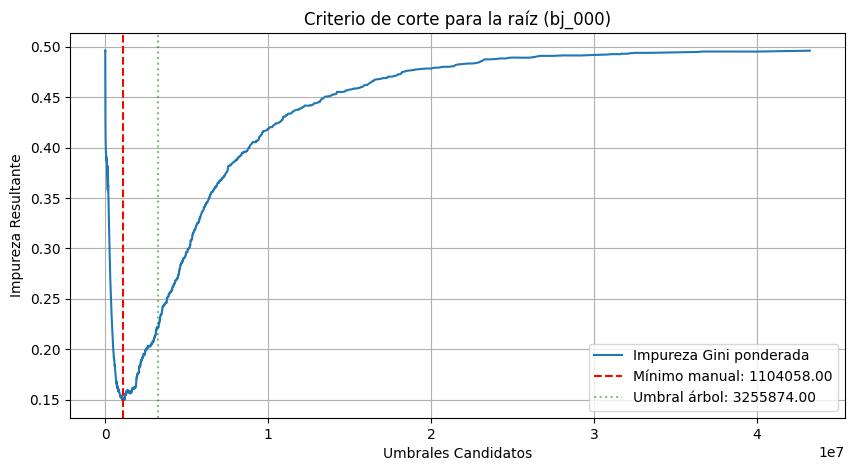

Mejor umbral calculado a mano: 1104058.0
Umbral reportado por el árbol: 3255874.0


In [ ]:
def gini(y, sample_weights=None):
    """Calcula la impureza de Gini considerando los pesos de las clases."""
    if len(y) == 0:
        return 0.0

    if sample_weights is None:
        sample_weights = np.ones(len(y))

    peso_total = np.sum(sample_weights)
    if peso_total == 0:
        return 0.0

    impureza = 1.0
    for clase in np.unique(y):
        # Suma de los pesos correspondientes a la clase actual
        p_clase = np.sum(sample_weights[y == clase]) / peso_total
        impureza -= p_clase ** 2

    return impureza

def impureza_ponderada(col, y, t, sample_weights=None):
    """Calcula el Gini ponderado de los dos nodos hijos al realizar el corte en t."""
    # Máscara para dividir los datos
    mascara_izq = col <= t
    y_izq = y[mascara_izq]
    y_der = y[~mascara_izq]

    w_izq = sample_weights[mascara_izq] if sample_weights is not None else None
    w_der = sample_weights[~mascara_izq] if sample_weights is not None else None

    # Calcular el peso total de cada nodo
    peso_total = len(y) if sample_weights is None else np.sum(sample_weights)
    peso_izq = len(y_izq) if sample_weights is None else np.sum(w_izq)
    peso_der = len(y_der) if sample_weights is None else np.sum(w_der)

    # Calcular impureza individual de cada hijo
    gini_izq = gini(y_izq, w_izq)
    gini_der = gini(y_der, w_der)

    # Retornar el promedio de las impurezas ponderadas por el tamaño del nodo
    return (peso_izq / peso_total) * gini_izq + (peso_der / peso_total) * gini_der

# --- Barrer umbrales sobre la variable de la raíz ---

# Obtener la variable de la raíz
indice_feature_raiz = arbol.tree_.feature[0]
nombre_feature_raiz = X_tr_i.columns[indice_feature_raiz]
col_raiz = X_tr_i[nombre_feature_raiz].values

# Replicar pesos del arbol con ponderación
pesos = np.where(y_tr == 0, C_FP, C_FN)

valores_unicos = np.sort(np.unique(col_raiz))
umbrales = (valores_unicos[:-1] + valores_unicos[1:]) / 2.0

# Barrido de umbrales
impurezas = []
for t in umbrales:
    imp = impureza_ponderada(col_raiz, y_tr, t, sample_weights=pesos)
    impurezas.append(imp)

# --- Grafico ---

# valores mínimos
idx_minimo = np.argmin(impurezas)
mejor_umbral_manual = umbrales[idx_minimo]
umbral_arbol = arbol.tree_.threshold[0]

plt.figure(figsize=(10, 5))
plt.plot(umbrales, impurezas, label='Impureza Gini ponderada', color='#1f77b4')
plt.axvline(mejor_umbral_manual, color='red', linestyle='--', label=f'Mínimo manual: {mejor_umbral_manual:.2f}')
plt.axvline(umbral_arbol, color='green', linestyle=':', alpha=0.5, label=f'Umbral árbol: {umbral_arbol:.2f}')

plt.title(f"Criterio de corte para la raíz ({nombre_feature_raiz})")
plt.xlabel("Umbrales Candidatos")
plt.ylabel("Impureza Resultante")
plt.legend()
plt.grid(True)
plt.show()

# 6. Imprimir verificación final
print(f"Mejor umbral calculado a mano: {mejor_umbral_manual}")
print(f"Umbral reportado por el árbol: {umbral_arbol}")

# TODO: barrer umbrales sobre la variable de la raiz y graficar
# TODO: comparar el minimo con arbol.tree_.threshold[0]

### 8c) (3 pts) Poda por costo-complejidad

Haz crecer un árbol profundo, obtén la secuencia de subárboles con `cost_complexity_pruning_path`, y grafica el costo del negocio en entrenamiento y en validación contra $\alpha$, junto con el número de hojas. Elige el $\alpha$ que minimiza el costo de validación.

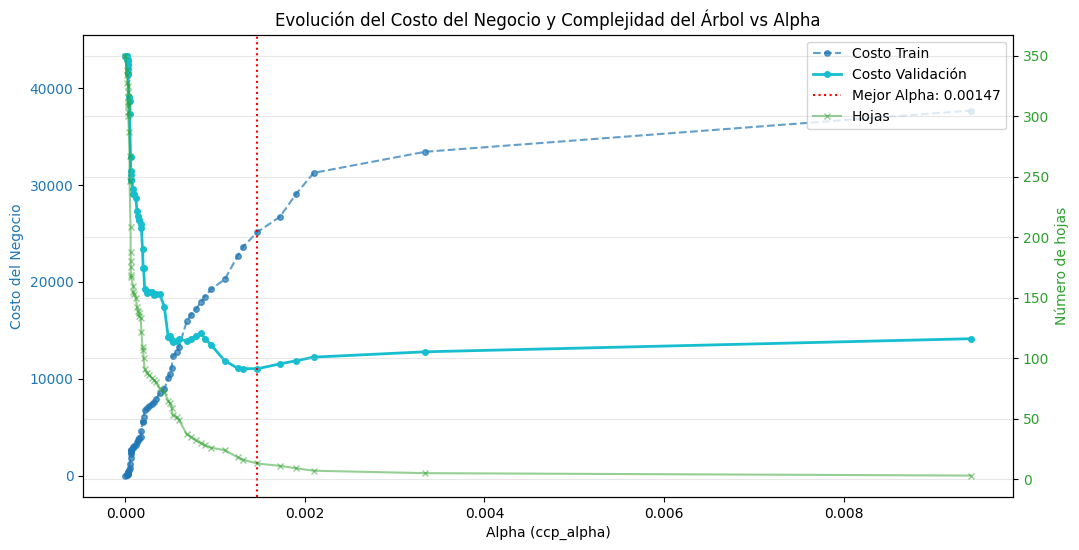

Mejor alpha encontrado: 0.001469
Costo mínimo en validación: 11020
Número de hojas del árbol óptimo: 13


In [ ]:
arbol_grande = DecisionTreeClassifier(class_weight={0: C_FP, 1: C_FN}, random_state=42)
path = arbol_grande.cost_complexity_pruning_path(X_tr_i, y_tr)
alphas = path.ccp_alphas[:-1]

# Submuestrear la grilla de alphas si son demasiados
paso = max(1, len(alphas) // 50)
alphas_sub = alphas[::paso]

costos_train = []
costos_val = []
num_hojas = []

# Ajustar un árbol por cada alpha
for alpha in alphas_sub:
    # Es vital mantener el class_weight y el random_state originales
    clf = DecisionTreeClassifier(random_state=42, class_weight={0: C_FP, 1: C_FN}, ccp_alpha=alpha)
    clf.fit(X_tr_i, y_tr)

    # Predicciones
    y_pred_tr = clf.predict(X_tr_i)
    y_pred_val = clf.predict(X_val_i)

    # Calcular costos y extraer hojas
    costos_train.append(costo_total(y_tr, y_pred_tr))
    costos_val.append(costo_total(y_val, y_pred_val))
    num_hojas.append(clf.tree_.n_leaves)

# Elegir el alpha que minimiza el costo de validación
idx_mejor = np.argmin(costos_val)
mejor_alpha = alphas_sub[idx_mejor]
mejor_costo = costos_val[idx_mejor]
mejor_num_hojas = num_hojas[idx_mejor]

# Graficar costo train/validacion y numero de hojas contra alpha
fig, ax1 = plt.subplots(figsize=(12, 6))

# Eje Y principal (Izquierda) - Costos
ax1.set_xlabel('Alpha (ccp_alpha)')
ax1.set_ylabel('Costo del Negocio', color='tab:blue')
ax1.plot(alphas_sub, costos_train, label='Costo Train', marker='o', markersize=4, linestyle='--', color='tab:blue', alpha=0.7)
ax1.plot(alphas_sub, costos_val, label='Costo Validación', marker='o', markersize=4, linestyle='-', color='tab:cyan', linewidth=2)
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.axvline(mejor_alpha, color='red', linestyle=':', label=f'Mejor Alpha: {mejor_alpha:.5f}')

# Eje Y secundario (Derecha) - Número de hojas
ax2 = ax1.twinx()
ax2.set_ylabel('Número de hojas', color='tab:green')
ax2.plot(alphas_sub, num_hojas, label='Hojas', marker='x', markersize=4, linestyle='-', color='tab:green', alpha=0.5)
ax2.tick_params(axis='y', labelcolor='tab:green')

# Leyendas
lineas_1, etiquetas_1 = ax1.get_legend_handles_labels()
lineas_2, etiquetas_2 = ax2.get_legend_handles_labels()
ax1.legend(lineas_1 + lineas_2, etiquetas_1 + etiquetas_2, loc='upper right')

plt.title("Evolución del Costo del Negocio y Complejidad del Árbol vs Alpha")
plt.grid(True, alpha=0.3)
plt.show()

# Reporte final
print(f"Mejor alpha encontrado: {mejor_alpha:.6f}")
print(f"Costo mínimo en validación: {mejor_costo}")
print(f"Número de hojas del árbol óptimo: {mejor_num_hojas}")

### 8d) (1 pt) ¿Dónde viste antes esa fórmula?

El criterio $C_\alpha(T) = \sum_j M_j Q_j(T) + \alpha |T|$ tiene la misma forma que algo de la Tarea 1. Nombra el concepto y di qué juega el papel de $\Omega$ aquí.

Respuesta 8d):

El concepto del que tiene la misma forma en su formula el criterio de $C_\alpha(T)$ es la regularización la cual siempre se compone de una funcion de error o perdida, en este caso $\sum_j M_j Q_j(T)$ tomarian dicho lugar y una función $\Omega$ que penaliza y aumenta el error de la estimación de perdida final bajo un criterio, el cual tiene cierta ponderación dada por un $\alpha$. en este caso la función $\Omega$ seria $|T|$, que es el numero de hojas que tiene un subtree que esta siendo evaluado, asi penalizado más fuerte aquellos arboles que consigan mayor profundidad o ajusten sobre mayor cantidad de umbrales

### 8e) (3 pts) La debilidad fatal

Entrena 25 árboles profundos, cada uno sobre una muestra bootstrap distinta del entrenamiento. Registra para cada uno la variable elegida en la raíz y su costo en validación. Reporta la tabla de frecuencias de la variable raíz y la dispersión de los costos.

In [ ]:
rng = np.random.default_rng(42)
raices, costos = [], []

# Se asume que X_tr_i es un DataFrame de Pandas y y_tr es un arreglo de NumPy
n_muestras = len(X_tr_i)
nombres_columnas = X_tr_i.columns

for b in range(25):
    # Muestra bootstrap (índices aleatorios con reemplazo)
    indices_boot = rng.choice(n_muestras, size=n_muestras, replace=True)
    X_boot = X_tr_i.iloc[indices_boot]
    y_boot = y_tr[indices_boot]

    # Entrenar árbol profundo (sin límite de profundidad, manteniendo los pesos)
    arbol_boot = DecisionTreeClassifier(class_weight={0: C_FP, 1: C_FN}, random_state=b)
    arbol_boot.fit(X_boot, y_boot)

    # Guardar variable raíz
    indice_raiz = arbol_boot.tree_.feature[0]
    nombre_raiz = nombres_columnas[indice_raiz]
    raices.append(nombre_raiz)

    # Guardar costo en validación
    y_pred_va = arbol_boot.predict(X_val_i)
    costos.append(costo_total(y_val, y_pred_va))

# Tabla de frecuencias de la raíz y estadísticas de los costos
frecuencias_raiz = pd.Series(raices).value_counts()
media_costos = np.mean(costos)
desv_costos = np.std(costos)

print("--- Tabla de frecuencias de la variable raíz ---")
print(frecuencias_raiz.to_string())
print("\n--- Dispersión de los costos en validación ---")
print(f"Media: {media_costos:.2f}")
print(f"Desviación estándar: {desv_costos:.2f}")

--- Tabla de frecuencias de la variable raíz ---
ck_000    21
ci_000     4

--- Dispersión de los costos en validación ---
Media: 49911.60
Desviación estándar: 3983.06


### 8f) (2 pts) Diagnóstico en el vocabulario del curso

Con esos números: ¿el problema de un árbol profundo es de aproximación o de estimación? Justifica, y anticipa qué le hace un promedio a cada una de las dos cantidades que aparecen en la descomposición.

Respuesta 8f):

Respuesta 8f): Dado lo visto en el resultado anterior podemos ver que los modelos de arboles manejan gran varianza ante el cambio de los datos, la alta varianza entre los modelos debido a los datos con estos utilizan bajo los conceptos del curso estan intimamente relacionados a un error de estimación, ocurrido por la complejidad del modelo que se ajusta fuertemente a los datos que tiene.

Directamente sobre la varianza que es el error de la descomposición con la que tiene problemas el desicion tree el cual tiene la siguiente forma:

$$\mathbb{E}_x \mathbb{E}_S \left[ (\widehat{f}_S(\boldsymbol{x}) - \bar{f}(\boldsymbol{x}))^2 \right]$$

Donde $\widehat{f}_S(\boldsymbol{x})$ terminaria siendo estimado para ser un promedio constante de los submuestreos. Este promedio no se puede asegurar que alcanze el promedio ideal $\bar{f}(\boldsymbol{x})$ pero si que podra acercarse más y reducir la varianza.

Con respecto al sesgo que es el asociado a los errores de aproximación al ser un termino que no requiere de $\widehat{f}_S(\boldsymbol{x})$ terminaria por no verse afectado.

## 9. Bagging y Random Forest

Si el tiempo de cómputo se hace incómodo en esta sección, trabaja con una submuestra estratificada del entrenamiento que conserve **todos** los positivos, y dilo explícitamente.

### 9a) (4 pts) El teorema de la varianza del promedio correlacionado, verificado

Con un bosque de $B=200$ árboles, obtén la matriz de predicciones individuales sobre validación (`[est.predict_proba(X_val)[:, 1] for est in bosque.estimators_]`) y:

1. estima $\sigma^2$ como la varianza promedio entre árboles en cada punto,
2. estima $\rho$ como la correlación promedio entre pares de árboles a lo largo de los puntos de validación,
3. divide los 200 árboles en subgrupos disjuntos de tamaño $B' \in \{1, 2, 5, 10, 20, 50\}$, calcula la varianza empírica del promedio de cada subgrupo,
4. superpón la curva teórica $\rho\sigma^2 + \frac{1-\rho}{B'}\sigma^2$.

In [ ]:
bosque = RandomForestClassifier(n_estimators=200,
                                class_weight={0: C_FP, 1: C_FN},
                                random_state=42,
                                n_jobs=-1)

bosque.fit(X_tr_i, y_tr)

# 2. Ahora sí puedes calcular la matriz P
P = np.array([est.predict_proba(X_val_i.values)[:, 1] for est in bosque.estimators_])

# TODO: sigma2 = varianza promedio entre arboles
# Calcula la varianza a lo largo del eje de los árboles (axis=0) y promedia sobre los puntos
sigma2 = np.mean(np.var(P, axis=0))

# TODO: rho = correlacion promedio entre pares de arboles
# np.corrcoef calcula la matriz de correlación (B x B)
matriz_corr = np.corrcoef(P)
# Se extraen los elementos por encima de la diagonal principal para evitar contar la autocorrelación (1.0)
indices_triangulo_superior = np.triu_indices_from(matriz_corr, k=1)
rho = np.mean(matriz_corr[indices_triangulo_superior])

tamanos = [1, 2, 5, 10, 20, 50]
# TODO: varianza empirica del promedio de subgrupos disjuntos, para cada tamano
var_empiricas = []
B_total = P.shape[0] # 200

for B_prima in tamanos:
    n_subgrupos = B_total // B_prima
    promedios_ensambles = []

    # 1. Formar los subgrupos y calcular el promedio (ensamble) de cada uno
    for i in range(n_subgrupos):
        subgrupo = P[i*B_prima : (i+1)*B_prima, :]
        promedios_ensambles.append(np.mean(subgrupo, axis=0))

    # 2. Calcular la varianza empírica de estos nuevos ensambles en cada punto y promediar
    var_empirica = np.mean(np.var(promedios_ensambles, axis=0))
    var_empiricas.append(var_empirica)

plt.figure(figsize=(9, 4.5))
# TODO: puntos empiricos + curva teorica + asintota rho*sigma2

# Puntos empíricos calculados con los subgrupos
plt.plot(tamanos, var_empiricas, 'ro', label="Varianza empírica", zorder=3)

# Curva teórica continua para B' desde 1 hasta 50
B_rango = np.linspace(1, 50, 100)
curva_teorica = rho * sigma2 + ((1 - rho) * sigma2) / B_rango
plt.plot(B_rango, curva_teorica, 'b-', label="Curva teórica")

# Asíntota que representa el límite matemático (el piso infranqueable)
plt.axhline(y=rho * sigma2, color='green', linestyle='--', label=r"Asíntota $\rho\sigma^2$")

plt.xlabel("B'")
plt.ylabel("Var del promedio")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 9b) (3 pts) El efecto de $m$ sobre la correlación

Ajusta Random Forests de 200 árboles con $m \in \{1, 4, 13, 40, 170\}$ atributos por corte. Nota que $m=170$ (todos los atributos) es exactamente **bagging**. Para cada uno reporta el $\rho$ estimado como en 9a), el AUC promedio de un árbol individual (la *fuerza*), y el AUC y el costo del bosque. Grafica $\rho$ y la fuerza contra $m$ en el mismo eje.

Ajustando bosques. Esto puede tomar unos minutos...

--- Resultados por cantidad de atributos (m) ---
  m      rho  fuerza_AUC_indiv  AUC_bosque  costo
  1 0.369558          0.724796    0.989803  57080
  4 0.416893          0.746178    0.981610  46600
 13 0.447272          0.755539    0.986392  47150
 40 0.462390          0.757265    0.986513  46210
170 0.464731          0.754177    0.985674  45260


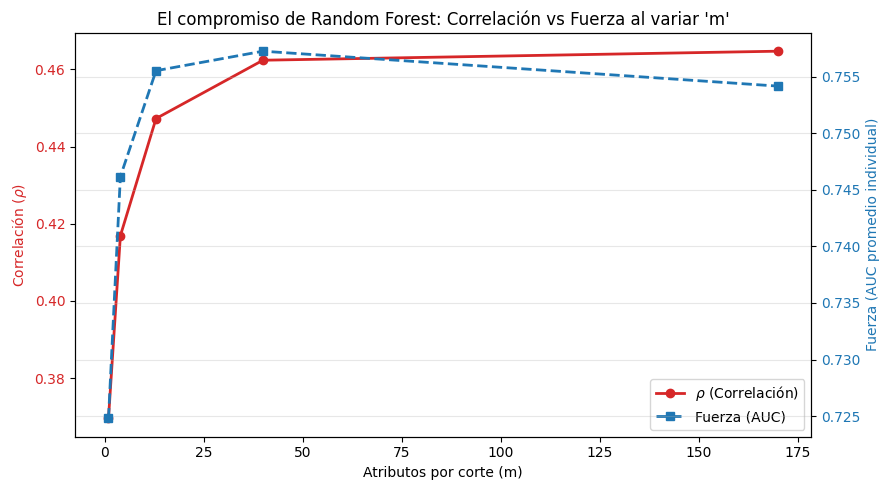

In [ ]:
ms = [1, 4, 13, 40, 170]
filas = []

print("Ajustando bosques. Esto puede tomar unos minutos...")

for m in ms:
    # 1. Ajustar Random Forest con max_features = m
    # Se recomienda n_jobs=-1 para paralelizar y acelerar el cómputo
    bosque = RandomForestClassifier(n_estimators=200,
                                    max_features=m,
                                    class_weight={0: C_FP, 1: C_FN},
                                    random_state=42,
                                    n_jobs=-1)
    bosque.fit(X_tr_i, y_tr)

    # 2. Extraer matriz P con las predicciones probabilísticas de cada árbol en validación
    P = np.array([est.predict_proba(X_val_i.values)[:, 1] for est in bosque.estimators_])

    # 3. Estimar rho (correlación promedio)
    matriz_corr = np.corrcoef(P)
    indices_triangulo_superior = np.triu_indices_from(matriz_corr, k=1)
    rho = np.mean(matriz_corr[indices_triangulo_superior])

    # 4. Estimar AUC medio individual (la fuerza)
    aucs_individuales = [roc_auc_score(y_val, P[i, :]) for i in range(P.shape[0])]
    auc_medio_indiv = np.mean(aucs_individuales)

    # 5. Estimar AUC del bosque y costo del negocio
    y_pred_proba_bosque = bosque.predict_proba(X_val_i)[:, 1]
    auc_bosque = roc_auc_score(y_val, y_pred_proba_bosque)

    y_pred_bosque = bosque.predict(X_val_i)
    costo_bosque = costo_total(y_val, y_pred_bosque)

    # 6. Guardar resultados
    filas.append({
        'm': m,
        'rho': rho,
        'fuerza_AUC_indiv': auc_medio_indiv,
        'AUC_bosque': auc_bosque,
        'costo': costo_bosque
    })

df_resultados = pd.DataFrame(filas)
print("\n--- Resultados por cantidad de atributos (m) ---")
print(df_resultados.to_string(index=False))

# 7. Gráfico de rho y fuerza contra m
fig, ax1 = plt.subplots(figsize=(9, 5))

# Eje Y principal (Izquierda) - Correlación (rho)
color_rho = 'tab:red'
ax1.set_xlabel('Atributos por corte (m)')
ax1.set_ylabel(r'Correlación ($\rho$)', color=color_rho)
ax1.plot(df_resultados['m'], df_resultados['rho'], marker='o', color=color_rho, linewidth=2, label=r'$\rho$ (Correlación)')
ax1.tick_params(axis='y', labelcolor=color_rho)

# Eje Y secundario (Derecha) - Fuerza (AUC)
ax2 = ax1.twinx()
color_fuerza = 'tab:blue'
ax2.set_ylabel('Fuerza (AUC promedio individual)', color=color_fuerza)
ax2.plot(df_resultados['m'], df_resultados['fuerza_AUC_indiv'], marker='s', color=color_fuerza, linewidth=2, linestyle='--', label='Fuerza (AUC)')
ax2.tick_params(axis='y', labelcolor=color_fuerza)

# Leyendas unificadas
lineas_1, etiquetas_1 = ax1.get_legend_handles_labels()
lineas_2, etiquetas_2 = ax2.get_legend_handles_labels()
ax1.legend(lineas_1 + lineas_2, etiquetas_1 + etiquetas_2, loc='lower right')

plt.title("El compromiso de Random Forest: Correlación vs Fuerza al variar 'm'")
plt.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

### 9c) (2 pts) La cota de Breiman, leída en tus números

La cota dice $PE^{*} \le \bar\rho(1-s^2)/s^2$. Con la tabla de 9b), explica por qué el mejor $m$ no es ni el más chico ni el más grande, e identifica cuál de los dos términos empeora en cada extremo.

Respuesta 9c): El problema surgijo para ambos extremos, tanto el $m$ mas pequeño o el $m$ mas grande (bagging) va directamente relacionado a la correlación y la fuerza de predicción que puede tener cada arbol individual al restringirle el hacer su predicción a un numero $m$ de caracteristicas seleccionadas de manera aleatoria en cada partición.

Directamente cuando el $m$ es muy grande, tanto la correlación de los miembros $\bar\rho$ como la $s^2$ suben. $s^2$ termina indicando el desempeño que cada arbol esta entregando en promedio, el cual sera mucho mejor a mayor cantidad de features uno le deje evaluar de manera aleatoria, ya que tendra la posibilidad de elegir umbrales mas efectivos, por lo tanto en el caso de bagging, es cuando mejor rendimiento pueden tener los miembros del ensamblado, pero dado al uso total de las features, la correlación igualmente se vuelve muy alta, aumentando dentro de la cota de Brieman la probabilidad de error.

El caso de solo un $m$ o muy pocos $m$ tambien es malo, ya que a pesar de bajar la correlación $\bar\rho$, igualmente baja $s^2$ ya que cada arbol tiene mucha menos libertad para seleccionar aleatoriamente sus variables y conseguir un mejor umbral, asi provocando que haya un peor desempeño general. Finalmente tanto para el caso donde no hay menos o mas features para seleccionar, la cota de Breinman mantiene cierto trade off. Pero segun lo visto en la tabla y en la grafica desplegada en ele ejercicio 9b), podemos ver que el mejor desempeño del modelo al final ocurre dentro de una cantidad de $m$ no tan grande (menos de la mitad de los disponibles), pero lo suficiente bajo para atacar la correlación y mantener un buen desempeño de los miembros del ensamblado.


### 9d) (2 pts) Out-of-bag: validación gratis

Ajusta el mejor bosque con `oob_score=True`, y usa `oob_decision_function_` para calcular el AUC y el costo out-of-bag. Compáralos con los de validación y reporta la diferencia.

In [ ]:
m_optimo = 40

# TODO: bosque con oob_score=True
bosque_oob = RandomForestClassifier(n_estimators=200,
                                    max_features=m_optimo,
                                    class_weight={0: C_FP, 1: C_FN},
                                    random_state=42,
                                    oob_score=True, # Parámetro clave encendido
                                    n_jobs=-1)

# Se ajusta sobre el conjunto de entrenamiento
bosque_oob.fit(X_tr_i, y_tr)

# TODO: AUC y costo OOB contra AUC y costo de validacion

# 1. Calcular métricas Out-of-Bag (OOB)
y_pred_proba_oob = bosque_oob.oob_decision_function_[:, 1]
auc_oob = roc_auc_score(y_tr, y_pred_proba_oob)

# Transformar probabilidades OOB a predicciones duras (0 o 1) para el costo
y_pred_oob = np.where(y_pred_proba_oob >= 0.5, 1, 0)
costo_oob = costo_total(y_tr, y_pred_oob)

# 2. Calcular métricas de Validación
# Recuerda usar .values si estabas teniendo problemas de warnings con los nombres de las columnas
y_pred_proba_val = bosque_oob.predict_proba(X_val_i)[:, 1]
auc_val = roc_auc_score(y_val, y_pred_proba_val)

y_pred_val = bosque_oob.predict(X_val_i)
costo_val = costo_total(y_val, y_pred_val)

# 3. Reportar resultados y diferencias
print(f"--- Comparación Out-of-Bag vs Validación (m={m_optimo}) ---")
print(f"AUC OOB:        {auc_oob:.6f}")
print(f"AUC Validación: {auc_val:.6f}")
print(f"Diferencia AUC: {abs(auc_oob - auc_val):.6f}\n")

print(f"Costo OOB:        {costo_oob}")
print(f"Costo Validación: {costo_val}")
print(f"Diferencia Costo: {abs(costo_oob - costo_val)}")

# Parte 6: La decisión final

## 10. El modelo, el umbral y lo que se le dice al jefe de mantenimiento

### 10a) (3 pts) Elige y reporta

Elige un modelo y un umbral usando **solo** validación, y recién entonces evalúa una vez sobre prueba. Reporta la matriz de confusión, precision, recall, F1, el costo total y el costo por camión.

In [ ]:
y_prob_rf = bosque_oob.predict_proba(X_val_i)[:, 1]

# 2. Definir la misma grilla de umbrales
umbrales_rf = np.logspace(-4, 0, 300)
costos_rf = []

# 3. Barrido de costo
for t in umbrales_rf:
    y_pred_t_rf = (y_prob_rf >= t).astype(int)
    costo_t_rf = costo_total(y_val, y_pred_t_rf)
    costos_rf.append(costo_t_rf)

costos_rf = np.array(costos_rf)

# 4. Obtener el mínimo
idx_min_rf = np.argmin(costos_rf)
umbral_empirico_rf = umbrales_rf[idx_min_rf]
costo_minimo_rf = costos_rf[idx_min_rf]

print("--- Evaluación de Umbrales para Random Forest ---")
print(f"Umbral óptimo empírico RF: {umbral_empirico_rf:.5f}")
print(f"Costo mínimo en validación: ${costo_minimo_rf:,}")

--- Evaluación de Umbrales para Random Forest ---
Umbral óptimo empírico RF: 0.06062
Costo mínimo en validación: $7,250


In [ ]:
modelo_elegido = bosque_oob
umbral_elegido = 0.06062 # El umbral óptimo empírico que acabas de encontrar

# El bosque se entrenó sobre los datos imputados (sin estandarizar)
datos_prueba = X_te_i

# --- 2. EVALUAR UNA ÚNICA VEZ EN PRUEBA ---
y_prob_prueba = modelo_elegido.predict_proba(datos_prueba)[:, 1]
y_pred_prueba = (y_prob_prueba >= umbral_elegido).astype(int)

# --- 3. CALCULAR MÉTRICAS ---
matriz_conf = confusion_matrix(y_te, y_pred_prueba)
precision = precision_score(y_te, y_pred_prueba)
recall = recall_score(y_te, y_pred_prueba)
f1 = f1_score(y_te, y_pred_prueba)

costo_final = costo_total(y_te, y_pred_prueba)
costo_por_camion = costo_final / len(y_te)

# --- 4. REPORTAR LA TABLA COMPLETA ---
print("=== EVALUACIÓN FINAL EN CONJUNTO DE PRUEBA ===")
print(f"Modelo utilizado: Random Forest (m=40)")
print(f"Umbral aplicado:  {umbral_elegido:.5f}\n")

print("Matriz de Confusión:")
print(matriz_conf)
print(f"  Verdaderos Negativos (TN): {matriz_conf[0,0]}")
print(f"  Falsos Positivos (FP):     {matriz_conf[0,1]}")
print(f"  Falsos Negativos (FN):     {matriz_conf[1,0]}")
print(f"  Verdaderos Positivos (TP): {matriz_conf[1,1]}\n")

print(f"Precision:        {precision:.4f}")
print(f"Recall:           {recall:.4f}")
print(f"F1-Score:         {f1:.4f}\n")

print(f"Costo Total:      ${costo_final:,}")
print(f"Costo por Camión: ${costo_por_camion:.2f}")

### 10b) (2 pts) ¿Cuánto se ganó?

Compara el costo de prueba de tu modelo contra los dos clasificadores triviales de 2a) y contra el mismo modelo con umbral 0,5. Expresa la mejora en porcentaje sobre el mejor de los triviales.

In [ ]:
costo_rf_optimo = costo_final

# 2. Costo del Random Forest con umbral por defecto (0.5)
y_pred_prueba_05 = (y_prob_prueba >= 0.5).astype(int)
costo_rf_05 = costo_total(y_te, y_pred_prueba_05)

# 3. Costos de los clasificadores triviales sobre el conjunto de PRUEBA
y_pred_nunca_te = np.zeros_like(y_te)
costo_nunca_te = costo_total(y_te, y_pred_nunca_te)

y_pred_todos_te = np.ones_like(y_te)
costo_todos_te = costo_total(y_te, y_pred_todos_te)

# 4. Encontrar el mejor de los triviales
mejor_trivial = min(costo_nunca_te, costo_todos_te)

# 5. Calcular el porcentaje de mejora sobre el mejor trivial
# Fórmula: ((Costo Trivial - Costo Modelo) / Costo Trivial) * 100
mejora_pct = ((mejor_trivial - costo_rf_optimo) / mejor_trivial) * 100

# 6. Crear y mostrar la tabla comparativa
datos_comparacion = {
    "Modelo en Prueba": [
        "Trivial: Nunca Revisar",
        "Trivial: Revisar Todos",
        "Random Forest (Umbral 0.5)",
        "Random Forest (Umbral Óptimo)"
    ],
    "Costo Total ($)": [
        costo_nunca_te,
        costo_todos_te,
        costo_rf_05,
        costo_rf_optimo
    ]
}

df_comparativa = pd.DataFrame(datos_comparacion)
df_comparativa["Costo Total ($)"] = df_comparativa["Costo Total ($)"].apply(lambda x: f"${x:,.0f}")

print("=== TABLA COMPARATIVA DE COSTOS EN PRUEBA ===")
print(df_comparativa.to_string(index=False))

print(f"\nMejora sobre el mejor clasificador trivial: {mejora_pct:.2f}%")

### 10c) (2 pts) La conversación

Escribe el párrafo que le entregarías al jefe de mantenimiento de la flota: cuántos camiones habría que revisar al mes con tu regla, cuántas fallas se atraparían, cuántas se escaparían, y qué pasaría con esas tres cifras si él te dijera que una falla en ruta le cuesta 1.500 y no 500. No hace falta reentrenar nada para responder lo último.

Respuesta 10c): Para presentarle esto al jefe de mantenimiento en base a nuestros resultados, le indicaría que usando nuestra regla actual el taller tendría que revisar 515 camiones al mes en total (es decir, sumar las 191 alarmas reales más las 324 revisiones preventivas por falsas alarmas). Con este volumen de trabajo, lograríamos atrapar 191 fallas en las instalaciones antes de que ocurran, y solamente se escaparían 9 fallas a la ruta.

Si luego él me indica que el costo de una falla en ruta es en realidad de \$1.500 y no \$500, esto altera el comportamiento del sistema directamente sin necesidad de reentrenar el modelo. Al subir fuertemente el costo de dejar salir un camión malo ($C_{FN}$), nuestro cálculo del umbral de decisión caería a un valor mucho más bajo, volviendo al modelo mucho más sensible y desconfiado.

En la práctica, esto haría que la cantidad de camiones a revisar en el taller aumente fuertemente por precaución, lo que a su vez nos permitiría atrapar más fallas de las que detectábamos antes, reduciendo la cantidad de fallas escapadas a un número casi nulo.